# Household Air Pollution & Childhood ARI — Data Cleaning and EDA
**ARCeH Externship · IPUMS-DHS extract `Child_Environmental_Health` <br>
· Cambodia 2014, Myanmar 2015, Timor-Leste 2016, Indonesia 2017, Philippines 2017**

---

## Notebook 1: Purpose
Turn the raw IPUMS-DHS extract into one analysis-ready dataset for all later models by:
1. Defining the study population (usual-resident children under 5 with a valid respiratory-symptom answer).
2. Building the outcome, exposure, and covariates from raw DHS codes, with the reasoning for each choice.
3. Exploring the data for quality, distributions, and unadjusted relationships.
4. Recording assumptions and limitations before any modelling.

**Future notebooks (subject to change):** Notebook 2 (statistical analysis) and Notebook 3 (stress testing) start from this notebook's output, `Child_Environmental_Health_Cleaned.csv`.

---

## Research Question

**Plain language:** Is household air pollution, measured by cooking fuel type and cooking location, associated with ARI symptoms among children under 5 in Cambodia, Indonesia, Myanmar, the Philippines, and Timor-Leste? The analysis accounts for wealth, maternal education, urban/rural residence, smoking in the home, breastfeeding, household size, and country.

**Variable form:** Is `solid_fuel` (polluting vs. clean fuel; kerosene counted as polluting per WHO 2014) associated with `ari` (cough in past 2 weeks + chest-related fast breathing, from COURECENT + COUCHESTPROB)?
- **Secondary exposures:** `kitchen_location` (3 levels) and the combined `hap_exposure_level` gradient.
- **Controls:** `wealth_quintile`, `mother_education`, `urban`, `smoking_in_home`, `ever_breastfed`, `household_size`, and `country` fixed effects.

**Hypothesis:** I expect polluting fuel use to be positively associated with ARI, and I expect the association to be strongest when that fuel is burned indoors without a separate kitchen. Smoke from solid fuel and kerosene inflames young children's airways, and an enclosed space concentrates the dose.

**Changes from the original question:**
- **Polluting fuel, not just solid fuel:** kerosene is grouped with biomass. `fuel_type_3cat` is kept to test this choice.
- **3-level kitchen location:** KITCHEN's "not in universe" code means cooking happens outdoors or in a separate building, so those households are kept as their own category instead of being dropped as missing.
- **Ever breastfed, not duration:** in 4 of 5 surveys, duration is recorded only for children still breastfeeding. Duration is used only for exploration and is not in the final dataset.
- **Country fixed effects:** pooling five surveys is only valid when comparisons are made within country.

**Notebook map** — each part has one header; individual steps are labelled inside the code cells (`# 2.1 …`).

| Part | Contents |
|---|---|
| 1. Setup & Load | Libraries, file paths, raw data |
| 2. Data Cleaning | Rename columns, study population filters, special codes → missing |
| 3. Feature Engineering | Outcome, exposures, covariates, variable roles |
| 4. EDA — Summary Statistics | Prevalence, exposure mix, covariate summaries (tables) |
| 5. Visualizations | Missingness, outcome, exposure and covariate charts |
| 6. Analysis-Ready Dataset | Complete cases, one-hot encoding, validation, export, verify |
| 7. Assumptions & Limitations | |
| 8. Next Steps | |

---
# Part 1 · Setup & Load
Libraries, plot style and file paths are fixed up front so every re-run gives identical output. The raw CSV is read-only; all work happens on an in-memory copy.

In [ ]:
# ______________________________________________________________________________
# 1.1  IMPORTS, SETTINGS & FILE PATHS
# Why: fixed seed, style and paths make the notebook fully reproducible.
# ______________________________________________________________________________


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')
np.random.seed(42)
warnings.filterwarnings('ignore', category=FutureWarning)    # silences pandas groupby.apply notices only

RAW_PATH   = 'Child_Environmental_Health.csv'               # raw IPUMS extract (read-only)
CLEAN_PATH = 'Child_Environmental_Health_Cleaned.csv'       # new output file, never overwrites raw

In [ ]:
# ______________________________________________________________________________
# 1.2  LOAD RAW EXTRACT
# Why: an untouched `raw` copy lets every cleaning step be audited against
#      the original values. The checks stop the notebook immediately if the
#      file is incomplete (e.g. a cut-off upload), instead of failing at 6.4.
# ______________________________________________________________________________

raw = pd.read_csv(RAW_PATH)
df  = raw.copy()

print(f'Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns')
print('Children per sample:')
print(raw.groupby(['COUNTRY', 'YEAR']).size())

# Guard: the full extract has 47,600 children from 5 surveys
assert raw.shape[0] == 47_600,      f'Expected 47,600 rows, got {raw.shape[0]:,} — re-upload the full CSV'
assert raw['COUNTRY'].nunique() == 5, 'Not all 5 countries are in the file — re-upload the full CSV'

Raw shape: 47,600 rows × 48 columns
Children per sample:
COUNTRY  YEAR
104      2015     4815
116      2014     7165
262      2016     7221
360      2017    17848
608      2017    10551
dtype: int64


---
# Part 2 · Data Cleaning
Make the raw extract readable and trustworthy: descriptive column names, a true child ID, the correct study population, and codebook "special codes" (97/98/99…) converted to real missing values.

In [ ]:
# ______________________________________________________________________________
# 2.1  RENAME COLUMNS + CREATE CHILD ID
# Why: IPUMS mnemonics (TOSMKHHFREQ, COUCHESTPROB) are unreadable in model
#      output. IDHSPID identifies the MOTHER, so siblings share it — a true
#      child key (mother ID + birth index) is needed for duplicate checks.
# ______________________________________________________________________________

rename_map = {
    # --- Survey design & identifiers ---
    'SAMPLE': 'sample_id', 'SAMPLESTR': 'sample_id_str', 'COUNTRY': 'country_code',
    'YEAR': 'survey_year', 'IDHSPID': 'person_id', 'IDHSHID': 'household_id_xsample',
    'DHSID': 'dhs_cluster_key', 'IDHSPSU': 'psu_id_xsample', 'IDHSSTRATA': 'strata_id_xsample',
    'CASEID': 'respondent_id', 'HHID': 'household_id_sample', 'PSU': 'psu_id_sample',
    'STRATA': 'strata_id_sample', 'DOMAIN': 'sampling_domain',
    'HHNUM': 'household_number_in_cluster', 'CLUSTERNO': 'cluster_number',
    'LINENO': 'respondent_line_number', 'BIDX': 'birth_history_index',
    'LINENOKID': 'child_line_number',

    # --- Weights ---
    'PERWEIGHT': 'sample_weight_person', 'KIDWT': 'population_factor_weight_child',
    'AWFACTT': 'all_woman_factor_total', 'AWFACTU': 'all_woman_factor_urban_rural',
    'AWFACTR': 'all_woman_factor_region', 'AWFACTE': 'all_woman_factor_education',
    'AWFACTW': 'all_woman_factor_wealth', 'DVWEIGHT': 'domestic_violence_module_weight',

    # --- Mother / household demographics ---
    'URBAN': 'urban_rural', 'AGE': 'mother_age', 'AGE5YEAR': 'mother_age_5yr_group',
    'RESIDENT': 'usual_resident_or_visitor', 'RELIGION': 'religion',
    'MARSTAT': 'mother_marital_status', 'CHEB': 'mother_children_ever_born',
    'CURRWORK': 'mother_currently_working', 'KIDSEX': 'child_sex',
    'HHMEMTOTAL': 'household_size',

    # --- Socioeconomic ---
    'WEALTHQ': 'wealth_quintile', 'WEALTHS': 'wealth_score',
    'EDUCLVL': 'mother_education_level', 'EDYRTOTAL': 'mother_education_years',

    # --- EXPOSURES ---
    'COOKFUEL': 'cooking_fuel_type', 'KITCHEN': 'has_separate_kitchen',
    'TOSMKHHFREQ': 'household_smoking_frequency',

    # --- Breastfeeding ---
    'BRSFEDMO': 'breastfeeding_duration_months', 'BRSFEDCAT': 'breastfeeding_status_cat',

    # --- OUTCOME components ---
    'COURECENT': 'child_cough_recent', 'COUCHESTPROB': 'child_breathing_chest_related',
}

df = df.rename(columns=rename_map)
unmapped = set(df.columns) - set(rename_map.values())
print('Columns not renamed (should be empty):', unmapped)

# IPUMS 'person' = the mother; a mother can have several children under 5.
# The child's unique key is mother ID + birth-history index.
df['child_id'] = df['person_id'].str.strip().str.replace(r'\s+', '_', regex=True) + '_b' + df['birth_history_index'].astype(str)
assert df['child_id'].is_unique
print(f"{df['child_id'].nunique():,} children from {df['person_id'].nunique():,} mothers")

Columns not renamed (should be empty): set()
47,600 children from 38,040 mothers


In [ ]:
# ______________________________________________________________________________
# 2.2  COUNTRY CODES → NAMES
# Why: country enters the model as a fixed effect and splits every chart.
# ______________________________________________________________________________

country_map = {104: 'Myanmar', 116: 'Cambodia', 262: 'Timor-Leste',
               360: 'Indonesia', 608: 'Philippines'}
df['country'] = df['country_code'].map(country_map)

assert df['country'].notna().all(), 'Unexpected country code in extract'
print(df['country'].value_counts())

country
Indonesia      17848
Philippines    10551
Timor-Leste     7221
Cambodia        7165
Myanmar         4815
Name: count, dtype: int64


In [ ]:
# ______________________________________________________________________________
# 2.3  DEFINE STUDY POPULATION (ROW FILTERS)
# Why: household variables (fuel, kitchen, smoking) describe USUAL residents,
#      so visitors would be misclassified. Cough NIU (99) = question not asked
#      (child not surviving) → no outcome. The attrition log documents the N.
# ______________________________________________________________________________

attrition = [('Raw extract', len(df))]

df = df[df['usual_resident_or_visitor'] == 1].copy()
attrition.append(('Usual residents only (visitors / missing residence removed)', len(df)))

df = df[df['child_cough_recent'] != 99].copy()
attrition.append(('Cough question applicable (NIU removed)', len(df)))

pd.DataFrame(attrition, columns=['step', 'n_children'])

,step,n_children
0,Raw extract,47600
1,Usual residents only (visitors / missing resid...,46591
2,Cough question applicable (NIU removed),45154


In [ ]:
# ______________________________________________________________________________
# 2.4  SPECIAL CODES → MISSING (NaN)
# Why: codes like 97/98/99 mean don't know / missing / NIU. Left as numbers
#      they distort means and coefficients. Codes come from the codebook.
#      Exceptions handled later: KITCHEN 9 (informative, see 3.3) and
#      breastfeeding 92/94 (weaned / never breastfed, see 3.5).
# ______________________________________________________________________________

missing_codes = {
    'urban_rural':                   [3],              # refugee camp (none expected)
    'wealth_quintile':               [8],
    'mother_education_level':        [8],
    'household_smoking_frequency':   [6, 8, 9],        # non-resident, missing, NIU
    'child_sex':                     [9],
    'cooking_fuel_type':             [995, 996, 997, 998, 999],
    'has_separate_kitchen':          [6, 8],           # 9 (NIU) intentionally kept
    'child_cough_recent':            [97, 98],
    'child_breathing_chest_related': [97, 98],         # 99 handled in outcome logic
}

before = {c: df[c].isin(v).sum() for c, v in missing_codes.items()}
for col, codes in missing_codes.items():
    df[col] = df[col].mask(df[col].isin(codes))

pd.Series(before, name='values set to NaN').to_frame()

,values set to NaN
urban_rural,0
wealth_quintile,0
mother_education_level,0
household_smoking_frequency,4
child_sex,0
cooking_fuel_type,35
has_separate_kitchen,46
child_cough_recent,270
child_breathing_chest_related,45


---
# Part 3 · Feature Engineering
Build the analysis variables from raw DHS codes. Key decisions:

- **Outcome `ari`** — DHS standard: cough in past 2 weeks + chest-related fast/difficult breathing.
- **Exposure `solid_fuel`** — WHO 2014: kerosene counted as polluting (tested later via `fuel_type_3cat`).
- **`kitchen_location`** — KITCHEN's NIU code = cooking outdoors / separate building, kept as its own level.
- **`ever_breastfed`** replaces duration — duration isn't recorded for weaned children in 4 of 5 surveys.

In [ ]:
# ______________________________________________________________________________
# 3.1  OUTCOME — ari (1 = ARI symptoms, 0 = none)
# Why: DHS ARI = cough + fast breathing + chest problem. The chest question is
#      only asked of children with fast breathing, so 11/13 imply both.
#      Nose-only (12) / other (16) = upper airway, not ARI. Cough with chest
#      NIU (99) = no fast breathing → not ARI. 0/1 makes the mean = prevalence.
# Caveat: Cambodia 2014 is a DHS-6 survey; the other four are DHS-7. The DHS-7
#      ARI indicator may not require a cough. To verify against the Guide to
#      DHS Statistics, and to test an alternative definition (Part 8).
# ______________________________________________________________________________

cough = df['child_cough_recent']
chest = df['child_breathing_chest_related']

df['ari'] = np.select(
    [cough.isna(),                                   # cough unknown
     cough == 10,                                    # no cough
     (cough == 24) & chest.isin([11, 13]),           # cough + chest-related fast breathing
     (cough == 24) & chest.isin([0, 12, 16, 99]),    # cough, but no chest-related fast breathing
     (cough == 24) & chest.isna()],                  # chest answer unknown
    [np.nan, 0, 1, 0, np.nan],
    default=np.nan,
)

print(df['ari'].value_counts(dropna=False))
print(f"\nUnweighted ARI prevalence: {df['ari'].mean():.2%}")

ari
0.0    43253
1.0     1588
NaN      313
Name: count, dtype: int64

Unweighted ARI prevalence: 3.54%


In [ ]:
# ______________________________________________________________________________
# 3.2  PRIMARY EXPOSURE — solid_fuel (1 = polluting, 0 = clean)
# Why: WHO 2014 / DHS: electricity, LPG, gas, biogas = clean; wood, charcoal,
#      coal, straw, dung, crop residue = polluting. Kerosene = polluting per
#      WHO (judgment call → fuel_type_3cat kept for sensitivity; matters most
#      for Indonesia). "Other" (800) excluded: exposure unknown.
# ______________________________________________________________________________

clean_codes     = [100, 220, 221, 222, 230, 299, 300, 320, 802]   # electricity, LPG/natural gas, biogas, ethanol, solar
kerosene_codes  = [240]
biomass_codes   = [310, 400, 410, 411, 500, 510, 520, 530, 540,   # coal, wood, charcoal, straw/grass,
                   550, 600, 700, 710, 720]                       # dung, crop residue

fuel = df['cooking_fuel_type']
df['fuel_type_3cat'] = np.select(
    [fuel.isin(clean_codes), fuel.isin(kerosene_codes), fuel.isin(biomass_codes)],
    ['clean', 'kerosene', 'solid_biomass'],
    default=None,
)
df['solid_fuel'] = df['fuel_type_3cat'].map({'clean': 0, 'kerosene': 1, 'solid_biomass': 1})

print(pd.crosstab(df['country'], df['fuel_type_3cat'], margins=True))

fuel_type_3cat  clean  kerosene  solid_biomass    All
country                                              
Cambodia         1374         1           5521   6896
Indonesia       11290      1374           4014  16678
Myanmar           676         0           3789   4465
Philippines      3115        48           7031  10194
Timor-Leste       660       230           5995   6885
All             17115      1653          26350  45118


In [ ]:
# ______________________________________________________________________________
# 3.3  SECONDARY EXPOSURE — kitchen_location + hap_exposure_level
# Why: KITCHEN = "separate kitchen room?", asked ONLY if cooking is inside the
#      house. NIU (9) therefore = cooks outdoors / separate building.
#      Dropping it would delete ~90% of Timor-Leste.
#        0 → indoor_no_separate_room      (highest exposure)
#        1 → indoor_separate_room
#        9 → outdoor_or_separate_building (lowest exposure)
#      hap_exposure_level combines fuel × location to test dose-response.
# ______________________________________________________________________________

df['kitchen_location'] = df['has_separate_kitchen'].map({
    0: 'indoor_no_separate_room',
    1: 'indoor_separate_room',
    9: 'outdoor_or_separate_building',
})

def hap_level(row):
    if pd.isna(row['solid_fuel']) or pd.isna(row['kitchen_location']):
        return None
    if row['solid_fuel'] == 0:
        return '0_clean_fuel'
    return {'outdoor_or_separate_building': '1_polluting_outdoor',
            'indoor_separate_room':         '2_polluting_indoor_separate_room',
            'indoor_no_separate_room':      '3_polluting_indoor_no_separate_room'}[row['kitchen_location']]

df['hap_exposure_level'] = df.apply(hap_level, axis=1)

print(pd.crosstab(df['country'], df['kitchen_location'], margins=True))
print()
print(df['hap_exposure_level'].value_counts(dropna=False).sort_index())

kitchen_location  indoor_no_separate_room  indoor_separate_room  outdoor_or_separate_building    All
country                                                                                             
Cambodia                             2229                  1085                          3571   6885
Indonesia                            2621                 12343                          1707  16671
Myanmar                              1835                  1141                          1496   4472
Philippines                          4870                  2709                          2617  10196
Timor-Leste                           294                   399                          6191   6884
All                                 11849                 17677                         15582  45108

hap_exposure_level
0_clean_fuel                           17099
1_polluting_outdoor                    13779
2_polluting_indoor_separate_room        6870
3_polluting_indoor_no_separate_room  

In [ ]:
# ______________________________________________________________________________
# 3.4  COVARIATES
# Why: urban → 0/1 (DHS 1/2 implies a meaningless unit change).
#      wealth quintiles are relative WITHIN each survey → need country FE.
#      education kept categorical (levels are not equally spaced).
#      smoking collapsed to never / daily / less_than_daily (sparse cells).
#      household_size kept continuous (crowding proxy; up to 26 is plausible).
#      child_female optional (not in RQ, known ARI risk factor).
# ______________________________________________________________________________

df['urban'] = df['urban_rural'].map({1: 1, 2: 0})

wealth_labels = {1: 'Q1_poorest', 2: 'Q2_poorer', 3: 'Q3_middle', 4: 'Q4_richer', 5: 'Q5_richest'}
df['wealth_quintile_label'] = df['wealth_quintile'].map(wealth_labels)

df['mother_education'] = df['mother_education_level'].map(
    {0: 'none', 1: 'primary', 2: 'secondary', 3: 'higher'})

df['smoking_in_home'] = df['household_smoking_frequency'].map(
    {0: 'never', 1: 'daily', 2: 'less_than_daily', 3: 'less_than_daily', 4: 'less_than_daily'})

df['child_female'] = df['child_sex'].map({1: 0, 2: 1})

df[['urban', 'wealth_quintile_label', 'mother_education', 'smoking_in_home',
    'child_female', 'household_size']].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
urban,45154.0,NaN,NaN,NaN,0.362581,0.480751,0.0,0.0,0.0,1.0,1.0
wealth_quintile_label,45154,5,Q1_poorest,12638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mother_education,45154,4,secondary,21344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking_in_home,45150,3,daily,22775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
child_female,45154.0,NaN,NaN,NaN,0.484985,0.49978,0.0,0.0,0.0,1.0,1.0
household_size,45154.0,NaN,NaN,NaN,5.953205,2.394211,1.0,4.0,5.0,7.0,26.0


In [ ]:
# ______________________________________________________________________________
# 3.5  BREASTFEEDING — ever_breastfed (model) + months (exploration only)
# Why: BRSFEDMO has numeric months for nearly all Indonesian children, but in
#      the other 4 countries ONLY for children still breastfeeding; ~17,000
#      weaned children are coded 92 with no months. Using duration would drop
#      ~37% (older children, non-random) and months-so-far ≈ child age.
#      ever_breastfed is measured identically in all five surveys.
#      breastfeeding_months is kept only for the 4.5 / 5.8 checks (which
#      also show mothers rounding to 12/18/24 months) and is dropped
#      before export in 6.3.
# ______________________________________________________________________________

bf = df['breastfeeding_duration_months']

df['ever_breastfed'] = np.select(
    [bf.between(0, 59), bf == 92, bf == 94],     # numeric months or weaned → ever; 94 → never
    [1, 1, 0],
    default=np.nan,                               # 93/96/97/98/99 → unknown
)
df['breastfeeding_months'] = bf.where(bf.between(0, 59))   # exploration only; dropped before export

print(pd.crosstab(df['country'], df['ever_breastfed'].fillna(-1), margins=True))
print('\nNumeric duration available, by country (share of children):')
print(df.groupby('country')['breastfeeding_months'].apply(lambda s: s.notna().mean()).round(3))

ever_breastfed  -1.0   0.0    1.0    All
country                                 
Cambodia           9   275   6616   6900
Indonesia        115   721  15865  16701
Myanmar            0    68   4404   4472
Philippines        0   822   9374  10196
Timor-Leste        6   212   6667   6885
All              130  2098  42926  45154

Numeric duration available, by country (share of children):
country
Cambodia       0.331
Indonesia      0.950
Myanmar        0.444
Philippines    0.376
Timor-Leste    0.332
Name: breastfeeding_months, dtype: float64


In [ ]:
# ______________________________________________________________________________
# 3.6  VARIABLE ROLES (ANALYSIS PLAN, FIXED BEFORE MODELLING)
# Why: fixing roles before modelling prevents choosing covariates after
#      seeing which ones make the result significant. Some choices were
#      informed by cleaning/EDA (e.g. ever_breastfed, kitchen NIU), so this
#      plan is data-informed, not pre-registered.
# ______________________________________________________________________________

OUTCOME            = 'ari'
PRIMARY_EXPOSURE   = 'solid_fuel'
SECONDARY_EXPOSURE = ['kitchen_location', 'hap_exposure_level', 'fuel_type_3cat']
COVARIATES_CAT     = ['wealth_quintile_label', 'mother_education', 'smoking_in_home', 'country']
COVARIATES_BIN     = ['urban', 'ever_breastfed']
COVARIATES_NUM     = ['household_size']
OPTIONAL           = ['child_female', 'breastfeeding_months']
DESIGN             = ['sample_weight_person', 'psu_id_xsample', 'strata_id_xsample', 'household_id_xsample']

roles = pd.DataFrame(
    [(OUTCOME, 'Outcome', 'binary 0/1')] +
    [(PRIMARY_EXPOSURE, 'Primary exposure (independent)', 'binary 0/1')] +
    [(v, 'Secondary exposure', 'categorical') for v in SECONDARY_EXPOSURE] +
    [(v, 'Covariate (confounder)', 'categorical') for v in COVARIATES_CAT] +
    [(v, 'Covariate (confounder)', 'binary 0/1') for v in COVARIATES_BIN] +
    [(v, 'Covariate (confounder)', 'continuous') for v in COVARIATES_NUM] +
    [(v, 'Optional / sensitivity', '') for v in OPTIONAL] +
    [(v, 'Survey design (not a predictor)', '') for v in DESIGN],
    columns=['variable', 'role', 'type'])
roles

,variable,role,type
0,ari,Outcome,binary 0/1
1,solid_fuel,Primary exposure (independent),binary 0/1
2,kitchen_location,Secondary exposure,categorical
3,hap_exposure_level,Secondary exposure,categorical
4,fuel_type_3cat,Secondary exposure,categorical
5,wealth_quintile_label,Covariate (confounder),categorical
6,mother_education,Covariate (confounder),categorical
7,smoking_in_home,Covariate (confounder),categorical
8,country,Covariate (confounder),categorical
9,urban,Covariate (confounder),binary 0/1


---
# Part 4 · EDA — Summary Statistics
Numeric checks before any charts: how complete the data are, how common ARI is, how fuel use is distributed, and whether cells are large enough to trust. Prevalences use the DHS sample weight (DHS oversamples some regions) and are **unadjusted**.

In [ ]:
# ______________________________________________________________________________
# 4.1  HELPERS & EDA FRAME
# Why: one weighted-rate function used by every table and chart below.
# ______________________________________________________________________________


def wrate(g, col=OUTCOME, w='sample_weight_person'):
    # Weighted mean of a 0/1 column (as %), ignoring missing values
    g = g.dropna(subset=[col])
    return np.average(g[col], weights=g[w]) * 100

eda = df.dropna(subset=[OUTCOME]).copy()
COUNTRY_ORDER = ['Cambodia', 'Indonesia', 'Myanmar', 'Philippines', 'Timor-Leste']
model_vars = [OUTCOME, PRIMARY_EXPOSURE, 'kitchen_location'] + COVARIATES_CAT + COVARIATES_BIN + COVARIATES_NUM

In [ ]:
# ______________________________________________________________________________
# 4.2  MISSING-DATA AUDIT (% by variable × country)
# Why: complete-case analysis is only safe if missingness is small and not
#      concentrated in one country.
# ______________________________________________________________________________


miss = df.groupby('country')[model_vars].apply(lambda g: g.isna().mean() * 100).T.round(2)
miss

country,Cambodia,Indonesia,Myanmar,Philippines,Timor-Leste
ari,0.57,0.89,0.56,0.49,0.73
solid_fuel,0.06,0.14,0.16,0.02,0.00
kitchen_location,0.22,0.18,0.00,0.00,0.01
wealth_quintile_label,0.00,0.00,0.00,0.00,0.00
mother_education,0.00,0.00,0.00,0.00,0.00
smoking_in_home,0.01,0.02,0.00,0.00,0.00
country,0.00,0.00,0.00,0.00,0.00
urban,0.00,0.00,0.00,0.00,0.00
ever_breastfed,0.13,0.69,0.00,0.00,0.09
household_size,0.00,0.00,0.00,0.00,0.00


In [ ]:
# ______________________________________________________________________________
# 4.3  OUTCOME SUMMARY — ARI prevalence
# Why: ARI is rare (single-digit %), which affects model choice and how many
#      predictors the model can support (events per predictor).
# ______________________________________________________________________________


print(f"Events (ARI=1): {int(eda[OUTCOME].sum()):,}  |  Non-events: {int((eda[OUTCOME]==0).sum()):,}")
print(f"Unweighted ARI prevalence: {eda[OUTCOME].mean():.2%}\n")

prev = eda.groupby('country').apply(wrate).reindex(COUNTRY_ORDER).round(2)
prev.rename('weighted_ari_pct').to_frame()

Events (ARI=1): 1,588  |  Non-events: 43,253
Unweighted ARI prevalence: 3.54%



/tmp/ipykernel_4561/3034489057.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  prev = eda.groupby('country').apply(wrate).reindex(COUNTRY_ORDER).round(2)


,weighted_ari_pct
country,
Cambodia,5.54
Indonesia,4.24
Myanmar,3.18
Philippines,1.26
Timor-Leste,1.62


In [ ]:
# ______________________________________________________________________________
# 4.4  EXPOSURE SUMMARY — fuel mix and ARI by fuel
# Why: each country needs children in both exposure groups; small ARI cell
#      counts make within-country rates noisy. Pooled vs within-country rates
#      can disagree (Simpson's paradox) — a key reason for country FE.
# ______________________________________________________________________________


# Weighted fuel mix by country (% of children)
mix = (pd.crosstab(eda['country'], eda['fuel_type_3cat'], values=eda['sample_weight_person'],
                   aggfunc='sum', normalize='index') * 100).reindex(COUNTRY_ORDER).round(1)
print('Fuel mix by country (% weighted):'); print(mix, '\n')

# Pooled ARI rate by exposure
pooled = eda.dropna(subset=[PRIMARY_EXPOSURE]).groupby(PRIMARY_EXPOSURE).apply(wrate).round(2)
print('Pooled weighted ARI %  (0 = clean, 1 = polluting):'); print(pooled, '\n')

# Within-country ARI rate by fuel type
by_fuel = (eda.dropna(subset=[PRIMARY_EXPOSURE])
              .groupby(['country', 'fuel_type_3cat']).apply(wrate).rename('ari_pct').reset_index())
print('Weighted ARI % by country × fuel type:')
print(by_fuel.pivot(index='country', columns='fuel_type_3cat', values='ari_pct').round(2), '\n')

# ARI case counts per cell (check for sparse cells)
print('ARI cases per country × fuel cell:')
print(pd.crosstab(eda['country'], eda['fuel_type_3cat'], values=eda[OUTCOME], aggfunc='sum'))

Fuel mix by country (% weighted):
fuel_type_3cat  clean  kerosene  solid_biomass
country                                       
Cambodia         16.9       0.0           83.1
Indonesia        77.0       3.5           19.5
Myanmar          17.6       0.0           82.4
Philippines      43.1       0.8           56.2
Timor-Leste       9.4       5.2           85.4 

Pooled weighted ARI %  (0 = clean, 1 = polluting):
solid_fuel
0.0    3.27
1.0    3.28
dtype: float64 



/tmp/ipykernel_4561/2402881251.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pooled = eda.dropna(subset=[PRIMARY_EXPOSURE]).groupby(PRIMARY_EXPOSURE).apply(wrate).round(2)
/tmp/ipykernel_4561/2402881251.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby(['country', 'fuel_type_3cat']).apply(wrate).rename('ari_pct').reset_index())


Weighted ARI % by country × fuel type:
fuel_type_3cat  clean  kerosene  solid_biomass
country                                       
Cambodia         5.66      0.00           5.53
Indonesia        3.98      3.37           5.41
Myanmar          2.57       NaN           3.31
Philippines      0.82      0.00           1.62
Timor-Leste      1.79      3.34           1.50 

ARI cases per country × fuel cell:
fuel_type_3cat  clean  kerosene  solid_biomass
country                                       
Cambodia         60.0       0.0          301.0
Indonesia       469.0      39.0          236.0
Myanmar          25.0       NaN          207.0
Philippines      33.0       0.0          108.0
Timor-Leste       8.0       6.0           95.0


In [ ]:
# ______________________________________________________________________________
# 4.5  COVARIATE SUMMARY
# Why: checks for impossible values and skew in the continuous variable.
# ______________________________________________________________________________


print('Household size:'); print(eda['household_size'].describe().round(2), '\n')
print('Breastfeeding months (numeric values only):')
print(eda.groupby('country')['breastfeeding_months'].describe().round(1))

Household size:
count    44841.00
mean         5.96
std          2.39
min          1.00
25%          4.00
50%          5.00
75%          7.00
max         26.00
Name: household_size, dtype: float64 

Breastfeeding months (numeric values only):
               count  mean   std  min  25%   50%   75%   max
country                                                     
Cambodia      2279.0  11.9   9.1  0.0  5.0  10.0  16.0  57.0
Indonesia    15762.0  15.1  10.1  0.0  6.0  15.0  24.0  59.0
Myanmar       1984.0  15.9  12.6  0.0  6.0  13.0  22.0  59.0
Philippines   3834.0  18.5  14.9  0.0  7.0  15.0  27.0  59.0
Timor-Leste   2276.0  12.6  11.2  0.0  4.0  10.0  17.0  59.0


---
# Part 5 · Visualizations
Charts of the Part 4 summaries. All rates are weighted and unadjusted — they describe patterns, they don't test the hypothesis.

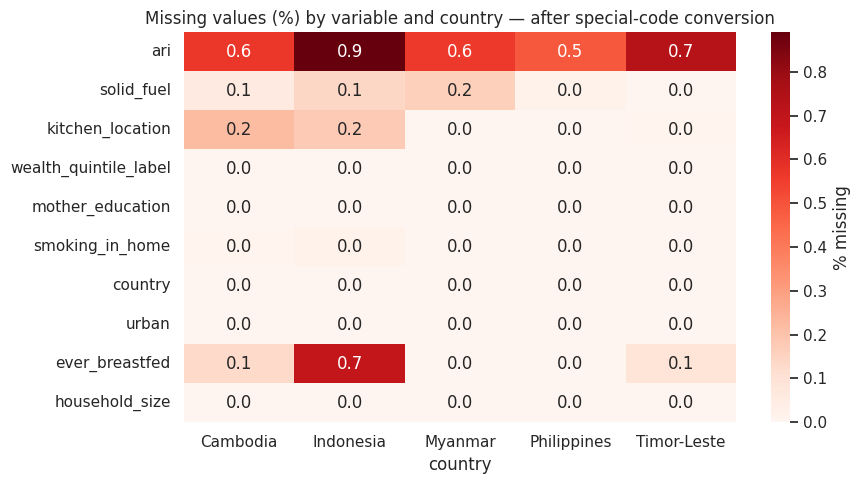

In [ ]:
# ______________________________________________________________________________
# 5.1  MISSINGNESS HEATMAP
# Why: shows at a glance whether any cleaning rule removes a whole survey.
# ______________________________________________________________________________


fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(miss, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': '% missing'}, ax=ax)
ax.set_title('Missing values (%) by variable and country — after special-code conversion')
plt.tight_layout(); plt.show()

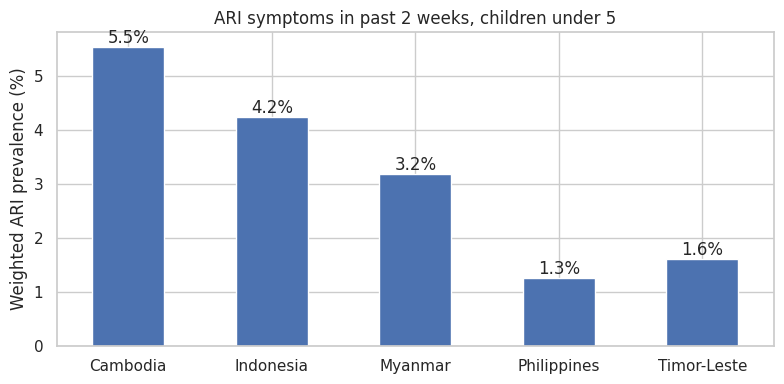

In [ ]:
# ______________________________________________________________________________
# 5.2  OUTCOME — ARI prevalence by country
# Why: baseline burden of ARI in each survey.
# ______________________________________________________________________________


ax = prev.plot.bar(color='#4C72B0', figsize=(8, 4), rot=0)
ax.bar_label(ax.containers[0], fmt='%.1f%%')
ax.set_ylabel('Weighted ARI prevalence (%)'); ax.set_xlabel('')
ax.set_title('ARI symptoms in past 2 weeks, children under 5')
plt.tight_layout(); plt.show()

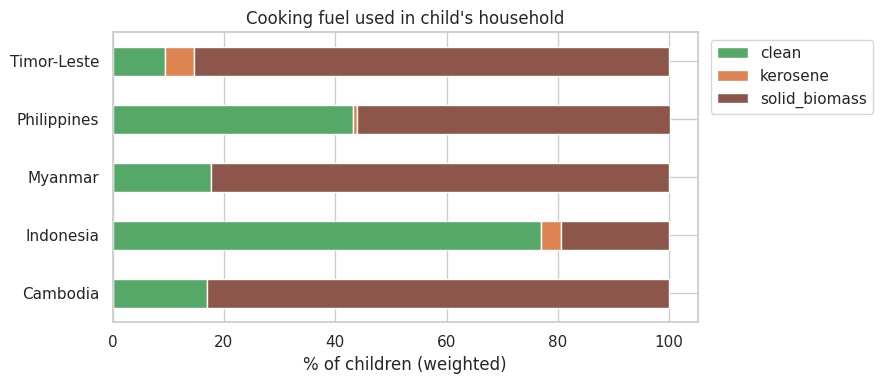

In [ ]:
# ______________________________________________________________________________
# 5.3  EXPOSURE — cooking fuel mix by country
# Why: shows where the clean/polluting contrast is informative and where
#      the kerosene decision matters (Indonesia).
# ______________________________________________________________________________


ax = mix[['clean', 'kerosene', 'solid_biomass']].plot.barh(
    stacked=True, figsize=(9, 4), color=['#55A868', '#DD8452', '#8C564B'])
ax.set_xlabel('% of children (weighted)'); ax.set_ylabel('')
ax.set_title("Cooking fuel used in child's household")
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

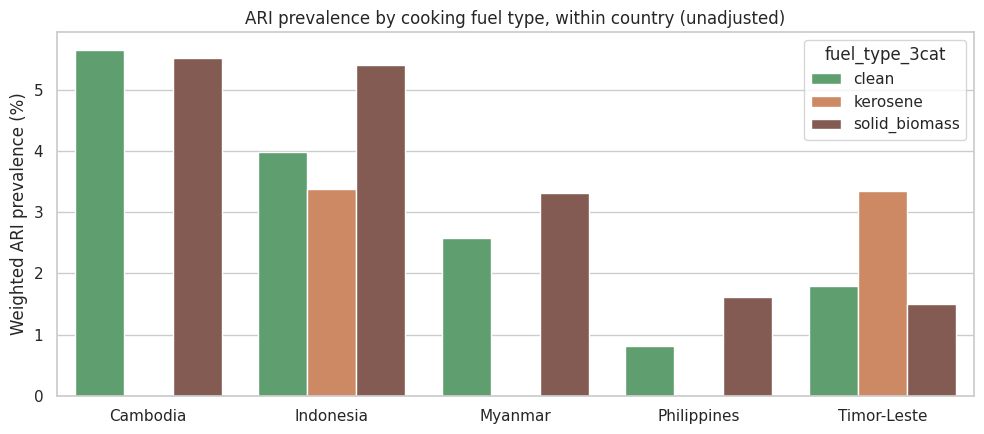

In [ ]:
# ______________________________________________________________________________
# 5.4  CORE RELATIONSHIP — ARI by fuel type, within country
# Why: unadjusted version of the research question; splitting by country
#      reveals patterns the pooled comparison hides.
# ______________________________________________________________________________


plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=by_fuel, x='country', y='ari_pct', hue='fuel_type_3cat', order=COUNTRY_ORDER,
                 hue_order=['clean', 'kerosene', 'solid_biomass'],
                 palette=['#55A868', '#DD8452', '#8C564B'])
ax.set_ylabel('Weighted ARI prevalence (%)'); ax.set_xlabel('')
ax.set_title('ARI prevalence by cooking fuel type, within country (unadjusted)')
plt.tight_layout(); plt.show()

/tmp/ipykernel_4561/129177083.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  k = eda.dropna(subset=['kitchen_location']).groupby('kitchen_location').apply(wrate)
/tmp/ipykernel_4561/129177083.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  h = eda.dropna(subset=['hap_exposure_level']).groupby('hap_exposure_level').apply(wrate).sort_index()


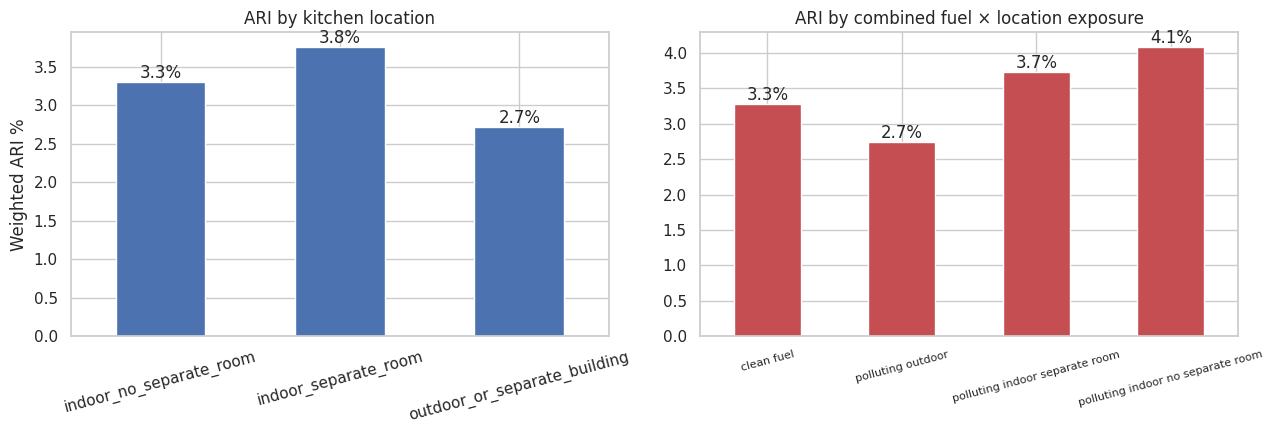

In [ ]:
# ______________________________________________________________________________
# 5.5  EXPOSURE GRADIENT — kitchen location and fuel × location
# Why: if household air pollution drives ARI, prevalence should rise from
#      clean → polluting outdoors → indoors w/ room → indoors w/o room.
# Note: these rates POOL all five countries, so they partly reflect country
#      composition (e.g. Timor-Leste is mostly outdoor). See 5.5b.
# ______________________________________________________________________________


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: kitchen location alone
k = eda.dropna(subset=['kitchen_location']).groupby('kitchen_location').apply(wrate)
k.plot.bar(ax=axes[0], color='#4C72B0', rot=15)
axes[0].bar_label(axes[0].containers[0], fmt='%.1f%%')
axes[0].set_title('ARI by kitchen location'); axes[0].set_ylabel('Weighted ARI %'); axes[0].set_xlabel('')

# Right: combined fuel × location gradient
h = eda.dropna(subset=['hap_exposure_level']).groupby('hap_exposure_level').apply(wrate).sort_index()
h.plot.bar(ax=axes[1], color='#C44E52', rot=15)
axes[1].bar_label(axes[1].containers[0], fmt='%.1f%%')
axes[1].set_title('ARI by combined fuel × location exposure'); axes[1].set_xlabel('')
axes[1].set_xticklabels([t.get_text()[2:].replace('_', ' ') for t in axes[1].get_xticklabels()], fontsize=8)

plt.tight_layout(); plt.show()

/tmp/ipykernel_4561/41986927.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  gw = hap.groupby(['country', 'hap_exposure_level']).apply(wrate).unstack().reindex(COUNTRY_ORDER)


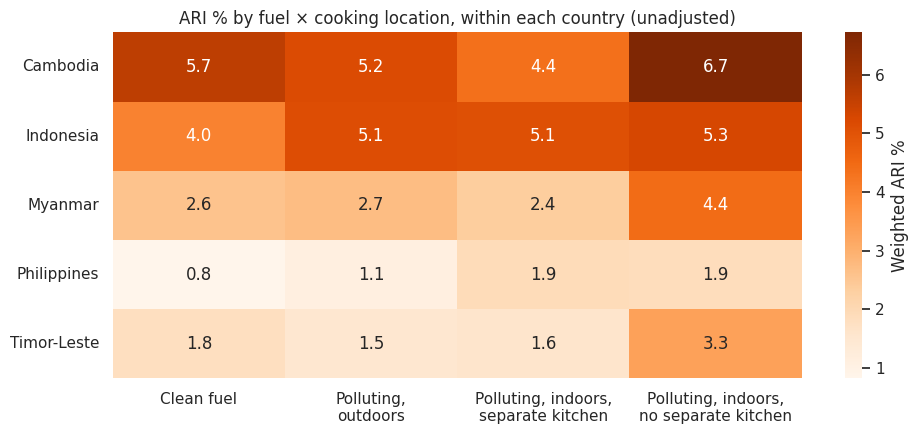

Weighted ARI % (rows = country):
hap_exposure_level  0_clean_fuel  1_polluting_outdoor  2_polluting_indoor_separate_room  3_polluting_indoor_no_separate_room
country                                                                                                                     
Cambodia                    5.66                 5.17                              4.37                                 6.72
Indonesia                   3.99                 5.12                              5.06                                 5.28
Myanmar                     2.57                 2.72                              2.36                                 4.45
Philippines                 0.82                 1.11                              1.92                                 1.86
Timor-Leste                 1.79                 1.54                              1.60                                 3.32 

ARI cases per cell:
hap_exposure_level  0_clean_fuel  1_polluting_outdoor  2_polluting_ind

In [ ]:
# ______________________________________________________________________________
# 5.5b EXPOSURE GRADIENT WITHIN EACH COUNTRY
# Why: the pooled gradient in 5.5 mixes countries with very different fuel and
#      kitchen patterns (the same Simpson's-paradox risk as 4.4). Splitting by
#      country shows which part of the pattern holds everywhere: polluting fuel
#      indoors with no separate kitchen is highest in four countries and
#      essentially tied in the Philippines (1.86% vs 1.92%); the levels in between are not consistent.
# ______________________________________________________________________________

hap = eda.dropna(subset=['hap_exposure_level'])

# Weighted ARI % for each country × exposure level
gw = hap.groupby(['country', 'hap_exposure_level']).apply(wrate).unstack().reindex(COUNTRY_ORDER)

# ARI case counts per cell (small counts = noisy rates)
gn = hap.groupby(['country', 'hap_exposure_level'])[OUTCOME].sum().unstack().reindex(COUNTRY_ORDER)

level_labels = ['Clean fuel', 'Polluting,\noutdoors',
                'Polluting, indoors,\nseparate kitchen', 'Polluting, indoors,\nno separate kitchen']

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(gw, annot=True, fmt='.1f', cmap='Oranges', cbar_kws={'label': 'Weighted ARI %'},
            xticklabels=level_labels, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('')
ax.set_title('ARI % by fuel × cooking location, within each country (unadjusted)')
plt.tight_layout(); plt.show()

print('Weighted ARI % (rows = country):'); print(gw.round(2), '\n')
print('ARI cases per cell:'); print(gn.astype(int))

/tmp/ipykernel_4561/428722877.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  r = eda.dropna(subset=[var]).groupby(var).apply(wrate).reindex(order)
/tmp/ipykernel_4561/428722877.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  r = eda.dropna(subset=[var]).groupby(var).apply(wrate).reindex(order)
/tmp/ipykernel_4561/428722877.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping

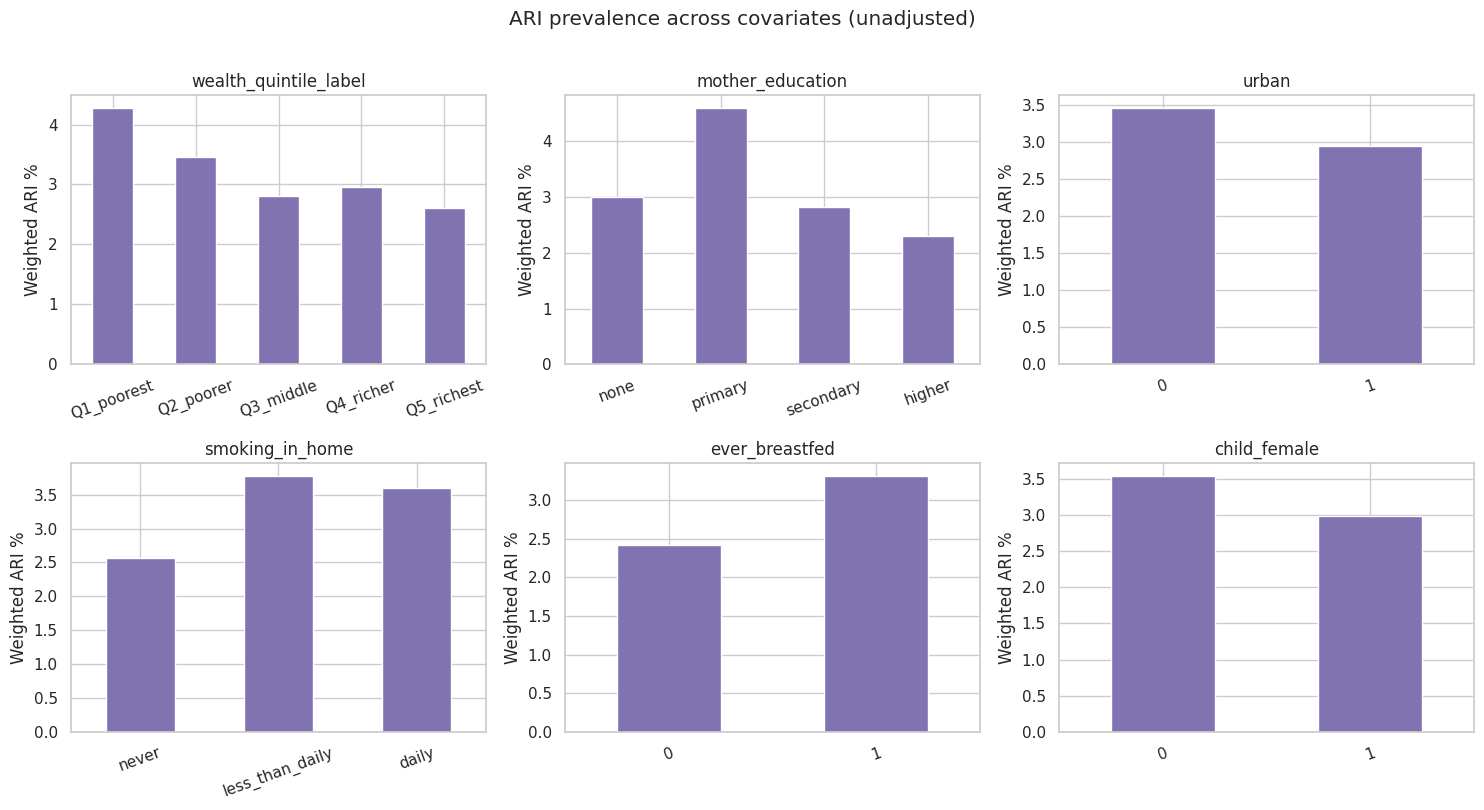

In [ ]:
# ______________________________________________________________________________
# 5.6  ARI ACROSS COVARIATES
# Why: a confounder must relate to BOTH ARI and fuel; this covers the ARI side.
# ______________________________________________________________________________


panels = [('wealth_quintile_label', ['Q1_poorest', 'Q2_poorer', 'Q3_middle', 'Q4_richer', 'Q5_richest']),
          ('mother_education',      ['none', 'primary', 'secondary', 'higher']),
          ('urban',                 [0, 1]),
          ('smoking_in_home',       ['never', 'less_than_daily', 'daily']),
          ('ever_breastfed',        [0, 1]),
          ('child_female',          [0, 1])]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (var, order) in zip(axes.flat, panels):
    r = eda.dropna(subset=[var]).groupby(var).apply(wrate).reindex(order)
    r.plot.bar(ax=ax, color='#8172B2', rot=20)
    ax.set_title(var); ax.set_xlabel(''); ax.set_ylabel('Weighted ARI %')
fig.suptitle('ARI prevalence across covariates (unadjusted)', y=1.01)
plt.tight_layout(); plt.show()

/tmp/ipykernel_4561/138641853.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: wrate(g, col=PRIMARY_EXPOSURE)).rename('pct').reset_index())
/tmp/ipykernel_4561/138641853.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: wrate(g, col=PRIMARY_EXPOSURE)).rename('pct').reset_index())


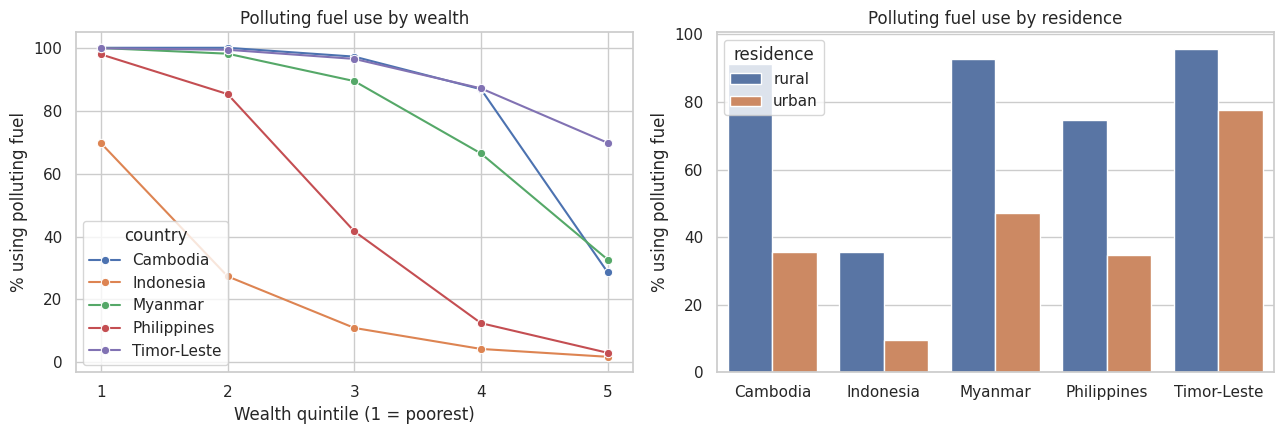

In [ ]:
# ______________________________________________________________________________
# 5.7  FUEL USE BY WEALTH & RESIDENCE
# Why: the fuel side of confounding: if polluting fuel tracks wealth closely,
#      the two compete for the same variance (checked in Notebook 2).
# ______________________________________________________________________________


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: polluting fuel use across wealth quintiles
w = (eda.dropna(subset=[PRIMARY_EXPOSURE])
        .groupby(['country', 'wealth_quintile'])
        .apply(lambda g: wrate(g, col=PRIMARY_EXPOSURE)).rename('pct').reset_index())
sns.lineplot(data=w, x='wealth_quintile', y='pct', hue='country', marker='o',
             hue_order=COUNTRY_ORDER, ax=axes[0])
axes[0].set_xticks([1, 2, 3, 4, 5]); axes[0].set_xlabel('Wealth quintile (1 = poorest)')
axes[0].set_ylabel('% using polluting fuel'); axes[0].set_title('Polluting fuel use by wealth')

# Right: polluting fuel use by urban/rural
u = (eda.dropna(subset=[PRIMARY_EXPOSURE])
        .groupby(['country', 'urban'])
        .apply(lambda g: wrate(g, col=PRIMARY_EXPOSURE)).rename('pct').reset_index())
u['residence'] = u['urban'].map({0: 'rural', 1: 'urban'})
sns.barplot(data=u, x='country', y='pct', hue='residence', order=COUNTRY_ORDER, ax=axes[1])
axes[1].set_ylabel('% using polluting fuel'); axes[1].set_xlabel('')
axes[1].set_title('Polluting fuel use by residence')

plt.tight_layout(); plt.show()

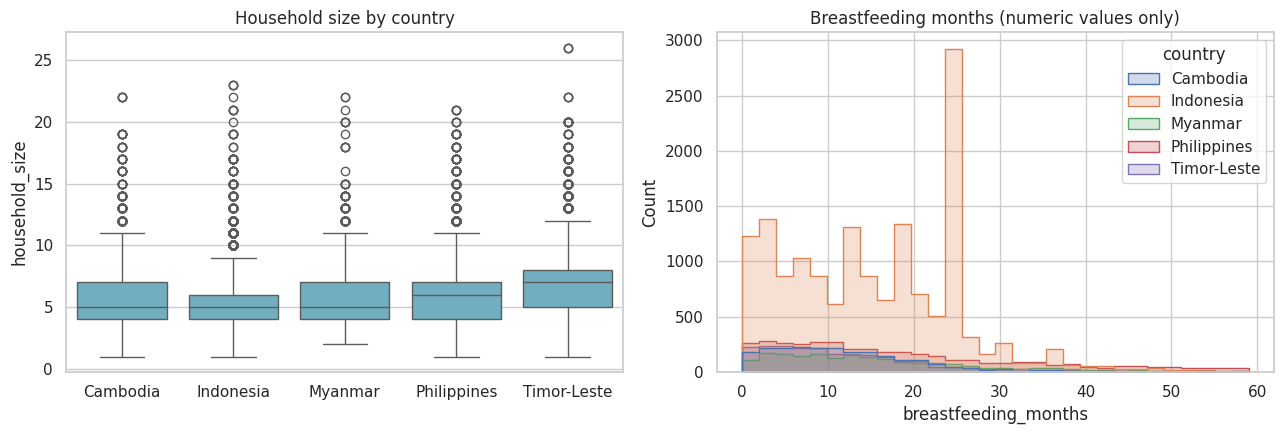

In [ ]:
# ______________________________________________________________________________
# 5.8  CONTINUOUS VARIABLES — household size & breastfeeding months
# Why: outliers/skew check; the histogram makes the breastfeeding coding
#      problem from 3.5 visible.
# ______________________________________________________________________________


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=eda, x='country', y='household_size', order=COUNTRY_ORDER, ax=axes[0], color='#64B5CD')
axes[0].set_title('Household size by country'); axes[0].set_xlabel('')

sns.histplot(data=eda, x='breastfeeding_months', hue='country', hue_order=COUNTRY_ORDER,
             bins=30, element='step', stat='count', ax=axes[1])
axes[1].set_title('Breastfeeding months (numeric values only)')

plt.tight_layout(); plt.show()

---
# Part 6 · Analysis-Ready Dataset
Lock one complete-case sample so every model in Notebook 2 uses the same children, encode categories with deliberate comparison baselines, validate, and export to a **new** file. (The fuel–wealth overlap check moves to Notebook 2, alongside the model diagnostics.)

**All five countries stay in the data and in the model.** For each categorical variable, the model needs one level as a *comparison baseline* (also called the reference group): the group every other level is compared against. Choosing a baseline does **not** filter anything out.

| Variable | Comparison baseline | Reason |
|---|---|---|
| wealth | Q1 poorest | risk change as wealth rises reads naturally |
| education | none | compare each level to no schooling |
| smoking | never | unexposed group |
| kitchen location | outdoor / separate building | lowest-exposure setting |
| country | Indonesia | largest survey → most stable baseline. All 5 countries are still analysed; any other country as baseline would give the same overall results |

In [ ]:
# ______________________________________________________________________________
# 6.1  COMPLETE-CASE ANALYTIC SAMPLE
# Why: logistic regression silently drops rows with any missing predictor;
#      one fixed sample keeps every model comparable. Only ~1% of eligible
#      children are lost, mostly for an unknown cough/chest answer.
# ______________________________________________________________________________

# Rows with every model variable present
analysis_vars = [OUTCOME, PRIMARY_EXPOSURE, 'kitchen_location'] + COVARIATES_CAT + COVARIATES_BIN + COVARIATES_NUM
complete = df[analysis_vars].notna().all(axis=1)

# Sequential log: children remaining after each non-missing requirement
attrition_cc = []
mask = pd.Series(True, index=df.index)
for var in analysis_vars:
    mask &= df[var].notna()
    attrition_cc.append((f'non-missing {var}', int(mask.sum())))

print(pd.DataFrame(attrition, columns=['step', 'n_children']).to_string(index=False))
print(pd.DataFrame(attrition_cc, columns=['step', 'n_children']).to_string(index=False))

# Kept vs dropped: large gaps would suggest complete-case bias
compare = pd.DataFrame({
    'kept':    df.loc[complete,  [OUTCOME, PRIMARY_EXPOSURE, 'urban']].mean(),
    'dropped': df.loc[~complete, [OUTCOME, PRIMARY_EXPOSURE, 'urban']].mean(),
}).mul(100).round(2)
print('\nMeans (%) among kept vs dropped children:'); print(compare)

# Final analytic sample (ad)
ad = df.loc[complete].copy()
print(f'\nAnalytic sample: {len(ad):,} children  |  ARI events: {int(ad[OUTCOME].sum()):,}')
print(ad['country'].value_counts())

                                                       step  n_children
                                                Raw extract       47600
Usual residents only (visitors / missing residence removed)       46591
                    Cough question applicable (NIU removed)       45154
                             step  n_children
                  non-missing ari       44841
           non-missing solid_fuel       44806
     non-missing kitchen_location       44760
non-missing wealth_quintile_label       44760
     non-missing mother_education       44760
      non-missing smoking_in_home       44756
              non-missing country       44756
                non-missing urban       44756
       non-missing ever_breastfed       44650
       non-missing household_size       44650

Means (%) among kept vs dropped children:
             kept  dropped
ari          3.55     2.62
solid_fuel  62.11    57.69
urban       36.19    42.06

Analytic sample: 44,650 children  |  ARI events: 1,583

In [ ]:
# ______________________________________________________________________________
# 6.2  ONE-HOT ENCODING WITH CHOSEN COMPARISON BASELINES
# Why: categories have no numeric spacing, so each level gets a 0/1 dummy.
#      One level per variable is dropped (dummy-variable trap); that level
#      becomes the baseline every odds ratio is compared against.
# Note: a baseline is NOT a filter. All 5 countries stay in the model.
#      Indonesia is only the country the other four are compared with;
#      its children are the rows where all 4 country columns are 0.
#      Alt. models: swap fuel+kitchen for hap_exposure_level, or solid_fuel
#      for fuel_type_3cat (kerosene sensitivity).
# ______________________________________________________________________________

reference = {
    'wealth_quintile_label': 'Q1_poorest',
    'mother_education':      'none',
    'smoking_in_home':       'never',
    'kitchen_location':      'outdoor_or_separate_building',
    'country':               'Indonesia',
}
cat_to_encode = list(reference.keys())

# Put the baseline level first so drop_first drops exactly that level
for col, ref in reference.items():
    levels = [ref] + sorted(l for l in ad[col].unique() if l != ref)
    ad[col] = pd.Categorical(ad[col], categories=levels)

# One-hot encode; binary 0/1 vars (solid_fuel, urban, ever_breastfed) left as is
encoded = pd.get_dummies(ad[cat_to_encode], drop_first=True, dtype=int)

# Main-model design matrix: fuel + kitchen + covariates + country FE
X = pd.concat([ad[[PRIMARY_EXPOSURE] + COVARIATES_BIN + COVARIATES_NUM].astype(float), encoded], axis=1)
y = ad[OUTCOME].astype(int)
weights  = ad['sample_weight_person']
clusters = ad['psu_id_xsample']        # for cluster-robust standard errors

print('Design matrix:', X.shape)
print(X.columns.tolist())
print(f'\nEvents per predictor: {y.sum() / X.shape[1]:.0f}  (rule of thumb: ≥ 10–20)')

Design matrix: (44650, 19)
['solid_fuel', 'urban', 'ever_breastfed', 'household_size', 'wealth_quintile_label_Q2_poorer', 'wealth_quintile_label_Q3_middle', 'wealth_quintile_label_Q4_richer', 'wealth_quintile_label_Q5_richest', 'mother_education_higher', 'mother_education_primary', 'mother_education_secondary', 'smoking_in_home_daily', 'smoking_in_home_less_than_daily', 'kitchen_location_indoor_no_separate_room', 'kitchen_location_indoor_separate_room', 'country_Cambodia', 'country_Myanmar', 'country_Philippines', 'country_Timor-Leste']

Events per predictor: 83  (rule of thumb: ≥ 10–20)


In [ ]:
# ______________________________________________________________________________
# 6.3  VALIDATION CHECKS & EXPORT
# Why: automated checks catch silent errors (stray 98s, all-zero dummies,
#      duplicate children) before modelling. Output goes to a NEW file.
#      breastfeeding_months is dropped at the very end: it is not used in
#      the analysis, and its blanks (most non-Indonesian children) would
#      only cause confusion in the cleaned file.
# ______________________________________________________________________________

assert y.isin([0, 1]).all(),                     'Outcome is not strictly 0/1'
assert X.notna().all().all(),                    'Missing values remain in X'
assert X[PRIMARY_EXPOSURE].isin([0, 1]).all(),   'Exposure is not strictly 0/1'
assert (X.std() > 0).all(),                      'A predictor has zero variance'
assert ad['child_id'].is_unique,                  'Duplicate children in analytic sample'
assert ad['household_size'].between(1, 40).all(),'Implausible household size'
print('All validation checks passed ✔')

# Export: IDs, design vars, analysis vars + prefixed dummies
keep_cols = (['child_id', 'person_id', 'household_id_xsample', 'psu_id_xsample', 'strata_id_xsample',
              'sample_weight_person', 'country', 'survey_year',
              OUTCOME, PRIMARY_EXPOSURE, 'fuel_type_3cat', 'kitchen_location', 'hap_exposure_level',
              'wealth_quintile', 'wealth_quintile_label', 'mother_education', 'urban',
              'smoking_in_home', 'ever_breastfed', 'household_size',
              'child_female', 'breastfeeding_months'])
analysis_ready = pd.concat([ad[keep_cols].reset_index(drop=True),
                            encoded.add_prefix('d_').reset_index(drop=True)], axis=1)
# Drop exploration-only column right before saving
analysis_ready = analysis_ready.drop(columns=['breastfeeding_months'])

analysis_ready.to_csv(CLEAN_PATH, index=False)
print(f'Saved {analysis_ready.shape[0]:,} rows × {analysis_ready.shape[1]} cols → {CLEAN_PATH}')

All validation checks passed ✔
Saved 44,650 rows × 36 cols → Child_Environmental_Health_Cleaned.csv


In [ ]:
# ______________________________________________________________________________
# 6.4  VERIFY EXPORTED FILE — all 5 countries present
# Why: rows keep the raw-file order, where Indonesia's survey happens to come
#      first, so the top of the file can look Indonesia-only. This confirms
#      every country made it through.
# ______________________________________________________________________________

check = pd.read_csv(CLEAN_PATH)

print(f'Rows: {len(check):,}  |  Columns: {check.shape[1]}\n')
print(check.groupby('country').agg(children=('ari', 'size'), ari_cases=('ari', 'sum')))
assert check['country'].nunique() == 5, 'A country is missing from the cleaned file'

Rows: 44,650  |  Columns: 36

             children  ari_cases
country                         
Cambodia         6833      358.0
Indonesia       16399      743.0
Myanmar          4440      232.0
Philippines     10144      141.0
Timor-Leste      6834      109.0


---
# Part 7 · Assumptions & Limitations

**Assumptions**
1. **ARI definition.** ARI = cough in the past 2 weeks + chest-related fast/difficult breathing (DHS standard). Because the fast-breathing question itself is not in the extract, chest-problem responses (COUCHESTPROB 11/13) are assumed to imply fast breathing, since the question is only asked of children with that symptom. **This definition may not be identical across surveys:** Cambodia 2014 is DHS-6 and the other four are DHS-7, whose ARI indicator may not require a cough. It will be verified against the Guide to DHS Statistics and tested with an alternative definition (Part 8).
2. **Kerosene = polluting.** Follows WHO 2014. Results should be re-run with `fuel_type_3cat` to show the finding doesn't hinge on this choice.
3. **KITCHEN NIU = cooking outside the main house.** Based on the DHS questionnaire skip pattern (the separate-room question is only asked when cooking is done inside the house). The cooking-location variable itself was not in the extract, so this is inferred, not observed.
4. **Missing at random.** Complete-case analysis assumes children dropped for missing data don't differ systematically on the fuel–ARI relationship. Step 6.1's kept-vs-dropped comparison supports, but cannot prove, this.
5. **Pooling is valid with country fixed effects.** Survey-relative measures (wealth quintiles) and country-specific "urban" definitions are assumed comparable *within* each country only; country dummies absorb between-country differences.

**Limitations**
1. **Cross-sectional design.** Exposure and symptoms are measured at the same time, so the study can show association, not causation.
2. **Self-reported, 2-week recall outcome.** Mothers report symptoms; no clinical diagnosis. Fast breathing is hard for caregivers to judge, so ARI is likely misclassified, which usually biases associations toward zero.
3. **Exposure is a proxy.** Fuel type and kitchen location stand in for actual PM2.5 exposure. Stove type, ventilation, time the child spends near the fire, and use of multiple fuels ("fuel stacking") are not captured.
4. **No child age variable in the extract.** Age is one of the strongest ARI risk factors and also drives breastfeeding status. Its absence is residual confounding. **Recommendation:** re-pull the extract with the child's current age in months before final modelling.
5. **Breastfeeding duration not harmonized across surveys** (Step 3.5). Duration is recorded only for children still breastfeeding in 4 of 5 surveys, and mothers round to 12/18/24 months (Step 5.8), so it was not analysed. The model uses `ever_breastfed`.
6. **Wealth–fuel overlap.** The DHS wealth index can include cooking fuel among its inputs, so adjusting for wealth may absorb part of the true fuel effect (over-adjustment). Report the model with and without wealth, and check the overlap (VIF) in Notebook 2.
7. **Clustered data.** Children are nested in mothers and households (siblings share exposure and often illness) and in survey clusters. Standard errors must be clustered on `psu_id_xsample` (or a survey-design estimator used); ordinary SEs would be too small.
8. **Weights.** `sample_weight_person` is normalized within each survey, so pooled weighted estimates are not population-proportional across countries. It is appropriate for within-country prevalence and for the pooled model with country fixed effects, but pooled "regional" prevalence figures should not be quoted. This includes the pooled figures in 4.4 (3.27% vs 3.28%) and 5.5: they show the Simpson's-paradox pattern but are not population estimates. A Mantel-Haenszel odds ratio stratified by country is the cleaner test.
9. **Survey years differ (2014–2017)** and seasonality of ARI differs by fieldwork month, which is not controlled for.
10. **Rare outcome.** ARI prevalence is low; country-specific models (especially Myanmar and Timor-Leste) will have few events and wide confidence intervals.
11. **Generalizability.** Results apply to children of interviewed women aged 15–49 in these five surveys; they don't automatically extend to other Southeast Asia / Western Pacific countries or later years.
12. **The fuel effect may differ by country.** The pooled model with country fixed effects estimates one average fuel effect. The descriptive results (4.4, 5.5b) suggest it may vary: higher with biomass in Indonesia, Myanmar and the Philippines, flat in Cambodia, reversed (on 8 cases) in Timor-Leste. A `solid_fuel × country` interaction must be tested.
13. **Pooled gradient vs within-country gradient.** The pooled exposure gradient in 5.5 partly reflects country composition. Within countries (5.5b), only the top level (polluting fuel indoors, no separate kitchen) is consistently highest (essentially tied in the Philippines, 1.86% vs 1.92%); the steps in between are not.
14. **Data-informed analysis plan.** Several decisions (ever_breastfed, kitchen NIU recovery, collapsing smoking levels) were made after exploring the data, though before any modelling. They are documented but not pre-registered.